# Stitching pt12: calibrated mismatch and conditioned gaps

Compare **Full HMM** and **greedy copying with conditioned gap HMMs** in
two 500 kb windows, chr20 **[1,000,000, 1,500,000)** in GRCh38 coordinates.
1KGP uses the existing `tsinfer-match-eval/data/sample_lists/tgp_chr20_n100.csv`
(100 diploid individuals). The error-containing Out-of-Africa dataset uses
all 300 individuals, retaining its genotype-error and phase masks. No new
data are simulated. Raw outputs share an inferred ancestor reference within
each dataset, with no simplification, dating or variant augmentation.

The only figures are the two recurrent-site quantities from pt11, recurrent
site/mutation overlap with injected genotype errors, and mean sample mutations
with mean copying switches stacked above them.

**Pipeline limitation found in this pilot:** the greedy shared-reference HMM
path assumes every reference mutation is derived. The calibrated ancestor
runs contain back mutations, which this representation does not encode.
Greedy leaves **117 / 516,800** called alleles incorrect in 1KGP and
**119 / 1,728,600** in simulation; Full HMM has zero disagreements in both.
The plots show the actual current pipeline outputs, but the greedy mutation
counts and comparisons are **provisional** until that representation is fixed.

In [1]:
import logging
import pathlib

import IPython.display as ipython_display

from ch5 import nb_plot, nb_utils

repository_dir = pathlib.Path.cwd()
logger = logging.getLogger(__name__)
logging.basicConfig(level=logging.INFO, format="%(message)s")
config_path = {
    "pipeline_dir": repository_dir.parent / "tsinfer-match-eval",
    "output_dir": repository_dir / "data/ch5/stitching_pt12_conditioning",
    "epsilon_per_haplotype_bp": 1e-05,
    "recombination_map": repository_dir
    / "data/general/HapMapII_GRCh38/genetic_map_Hg38_chr20.txt",
    "datasets": [
        {
            "name": "tgp_chr20_n100_500kb",
            "label": "1KGP chr20 · 100 individuals",
            "zarr_path": repository_dir / "data/general/zarr_vcfs/tgp/chr20/data.zarr",
            "sample_list": repository_dir.parent
            / "tsinfer-match-eval/data/sample_lists/tgp_chr20_n100.csv",
            "region": [1000000, 1500000],
            "ancestral_field": "variant_ancestral_allele",
            "exclude_masks": [
                "variant_not_snps_mask",
                "variant_not_biallelic_mask",
                "variant_bad_ancestral_mask",
                "variant_duplicate_position_mask",
            ],
            "truth_path": None,
            "raw_zarr_path": None,
        },
        {
            "name": "out_of_africa_n300_500kb_error",
            "label": "Simulation · 300 individuals",
            "zarr_path": repository_dir.parent
            / "tsinfer-anc-eval/data/match_eval/zarr_vcfs/OutOfAfrica_3G09-chr20-L0-R1e7-n300-s1-rep0-geno-1.0-phase3e-4-mispol0.zarr",
            "sample_list": None,
            "region": [1000000, 1500000],
            "ancestral_field": "variant_mispolarised_ancestral_state",
            "exclude_masks": [],
            "truth_path": repository_dir.parent
            / "tsinfer-anc-eval/data/match_eval/simulated/OutOfAfrica_3G09-chr20-L0-R1e7-n300-s1-rep0.trees",
            "raw_zarr_path": repository_dir.parent
            / "tsinfer-anc-eval/data/match_eval/zarr_vcfs/OutOfAfrica_3G09-chr20-L0-R1e7-n300-s1-rep0-raw.zarr",
        },
    ],
    "pipeline": {
        "focal_choice": "left",
        "af_cutoff": 0.1,
        "min_region_size_kb": 25,
        "ancestor_chunk_size": 5000,
        "inference_threads": 18,
        "matching_threads": 9,
        "sample_reader_threads": 1,
        "sample_prefetch_chunks": 2,
        "max_pending_haplotypes": None,
        "helper_threads": {
            "blosc_threads": 1,
            "zarr_async_concurrency": 1,
            "zarr_threading_max_workers": 1,
            "blas_threads": 1,
        },
    },
    "storage": {"variant_chunk": 1000, "sample_chunk": 100},
}
config_path["base_dir"] = repository_dir
config = nb_utils.conditioning_load_config(config_path)
plot_config = config

/Users/duncan/work/dphil-analysis/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## From errors per haplotype-bp to a mismatch probability

Assume **ε = 10⁻⁵ errors per haplotype-bp** for both datasets. Chapter 4's
[initial_testing](../ch4/initial_testing.py) reports a Tier 3 1KGP chr17
estimate of about 1.08 × 10⁻⁵; here 10⁻⁵ is an assumed transfer to chr20
and the simulation, not a newly fitted or independently validated rate.

The precise earlier guidance is in the Codex discussion of **24 September
2026**, [`rollout-2026-09-24T08-46-39`](/Users/duncan/.codex/sessions/2026/09/24/rollout-2026-09-24T08-46-39-01a0d261-7b35-7c22-bd1f-d586bacd118e.jsonl).
The [archived 29 September discussion](/Users/duncan/exo/archive/journals/this_week_2026-09-27_to_2026-10-03.org)
agrees that emissions can be constant while map-based transition costs vary.
The archived discussion separates unit conversion from empirical calibration.

With **S quality-filtered source variant sites** in an analysed span **L bp**,
the average density is λ = S/L and

$$p_{\mathrm{mismatch}} = \frac{\epsilon}{\lambda}
    = \epsilon\frac{L}{S}.$$

Equating εL expected errors per haplotype to Sp gives this linear conversion.
There is **no factor of two**: ε is already per haplotype. Here L is the
requested 500,000 bp window, not the retained chromosome length. S counts
regional source sites after fixed quality/ancestry filters, **before** the
selected cohort's singleton and monomorphic-site exclusions. Replacing S
with the smaller HMM site count would inflate p just because the cohort or
inference filters changed. All retained sites have one row per position and
known biallelic ancestry; 1KGP also uses its SNP/biallelic/bad-ancestry/duplicate
masks. We assume this average per-site error probability transfers to the
inference subset. The original chapter 4 chr17 masks differ, so this is a
transparent working assumption rather than a re-estimate on the same sites.

In [2]:
if __name__ == "__main__":
    calibration = nb_utils.prepare(config)
    columns = [
        "label",
        "span_bp",
        "num_individuals",
        "calibration_sites",
        "segregating_sites",
        "expected_inference_sites",
        "sites_per_bp",
        "epsilon_per_haplotype_bp",
        "mismatch_probability",
    ]
    ipython_display.display(calibration[columns])

,label,span_bp,num_individuals,calibration_sites,segregating_sites,expected_inference_sites,sites_per_bp,epsilon_per_haplotype_bp,mismatch_probability
0,1KGP chr20 · 100 individuals,500000,100,9837,3455,2584,0.019674,0.00001,0.000508
1,Simulation · 300 individuals,500000,300,4500,4386,2881,0.009000,0.00001,0.001111


## Recombination map and conditioned matching

All three matching stages (ancestors, Full HMM samples, greedy gap HMMs) use
the same chr20 HapMapII GRCh38 map and the dataset's calculated p. The pipeline
integrates the three-column cM/Mb map into a cumulative map. At adjacent
**actual inference positions**, tsinfer computes genetic distance dᵢ in
Morgans and uses

$$r_i = \frac{1-e^{-2d_i}}{2}, \qquad P(\mathrm{match})=1-p,
      \quad P(\mathrm{mismatch})=p.$$

Thus local recombination costs automatically reflect the map and site spacing;
p is passed directly as a constant emission probability. No mismatch-ratio
inversion or further multiplication/division by recombination is needed.
These checks confirm the parameter units and implementation, not an empirical
optimum for p. Absolute genomic coordinates are retained in both inputs.

Greedy uses **AF ≤ 0.1** and a **25 kb mean-density equivalent** minimum
connected focal region, the small-cohort setting from pt11. Exact copying
remains fixed. Residual gaps condition on available left and right copied
parents with native `initial_state` / `final_state`; their flanking
observations supply the seam transition costs. Supported one-site gaps use
the existing direct-copy rule and add a sample mutation when necessary.
This does not globally optimise the greedy cover. Both methods see the same
reference and HMM parameters. The existing pipeline runs with all available
cores; only ordinary matching targets are run, without its diagnostic suite.

In [3]:
if __name__ == "__main__":
    nb_utils.run_pipeline(config)
    tables = nb_utils.analyse(config)
    columns = [
        "label",
        "inference_sites",
        "mismatch_probability",
        "median_genetic_distance_morgans",
        "median_recombination_probability",
        "min_recombination_probability",
        "max_recombination_probability",
    ]
    ipython_display.display(tables.calibration[columns])
    ipython_display.display(tables.allele_checks)

Running tgp_chr20_n100_500kb; log: /Users/duncan/work/dphil-analysis/data/ch5/stitching_pt12_conditioning/tgp_chr20_n100_500kb/pipeline.log


Running out_of_africa_n300_500kb_error; log: /Users/duncan/work/dphil-analysis/data/ch5/stitching_pt12_conditioning/out_of_africa_n300_500kb_error/pipeline.log


,label,inference_sites,mismatch_probability,median_genetic_distance_morgans,median_recombination_probability,min_recombination_probability,max_recombination_probability
0,1KGP chr20 · 100 individuals,2584,0.000508,6.957554e-07,6.957550e-07,2.840700e-10,0.000212
1,Simulation · 300 individuals,2881,0.001111,6.085609e-07,6.085605e-07,8.273700e-10,0.000305


,dataset,label,method,called_alleles_checked,allele_disagreements
0,tgp_chr20_n100_500kb,1KGP chr20 · 100 individuals,full_hmm,516800,0
1,tgp_chr20_n100_500kb,1KGP chr20 · 100 individuals,greedy,516800,117
2,out_of_africa_n300_500kb_error,Simulation · 300 individuals,full_hmm,1728600,0
3,out_of_africa_n300_500kb_error,Simulation · 300 individuals,greedy,1728600,119


The allele check is a table, with no additional validation figure. Greedy's
[`share_reference`](../../../tsinfer-match-eval/lib/haplotypes.py) exports mutation
site/node arrays, and native `MatcherIndexes.from_prepared` assumes those
mutations all have allele code 1. The native Full HMM instead passes actual
encoded mutation states, including code 0 for back mutations. This distinction
matters when the calibrated ancestor references contain back mutations. A direct native index
control is recorded alongside the data; fixing the shared representation is
a separate pipeline change, not an adjustment to the requested p conversion.

## Recurrent sites (pt11 definitions)

A recurrent site has **at least two mutation records**, including back
mutations. Percentages use **all saved inference sites** as the denominator;
the conditional mean includes the first mutation record. An empty recurrent
set has an undefined mean. Raw trees include reference mutations as in pt11.
Simulation truth is evaluated at exactly the same inference positions with
the same 300-individual cohort. There is no truth panel for real 1KGP.

,dataset,label,method,num_sites,recurrent_sites,recurrent_site_percentage,mutations_at_recurrent_sites,mean_mutations_per_recurrent_site,additional_mutations
0,tgp_chr20_n100_500kb,1KGP chr20 · 100 individuals,full_hmm,2584,1253,48.490712,5964,4.759777,4711
1,tgp_chr20_n100_500kb,1KGP chr20 · 100 individuals,greedy,2584,1154,44.659443,5858,5.076256,4704
2,out_of_africa_n300_500kb_error,Simulation · 300 individuals,full_hmm,2881,2120,73.585561,12647,5.965566,10527
3,out_of_africa_n300_500kb_error,Simulation · 300 individuals,greedy,2881,1732,60.118015,11403,6.583718,9671
4,out_of_africa_n300_500kb_error,Simulation · 300 individuals,truth,2881,13,0.451232,26,2.000000,13


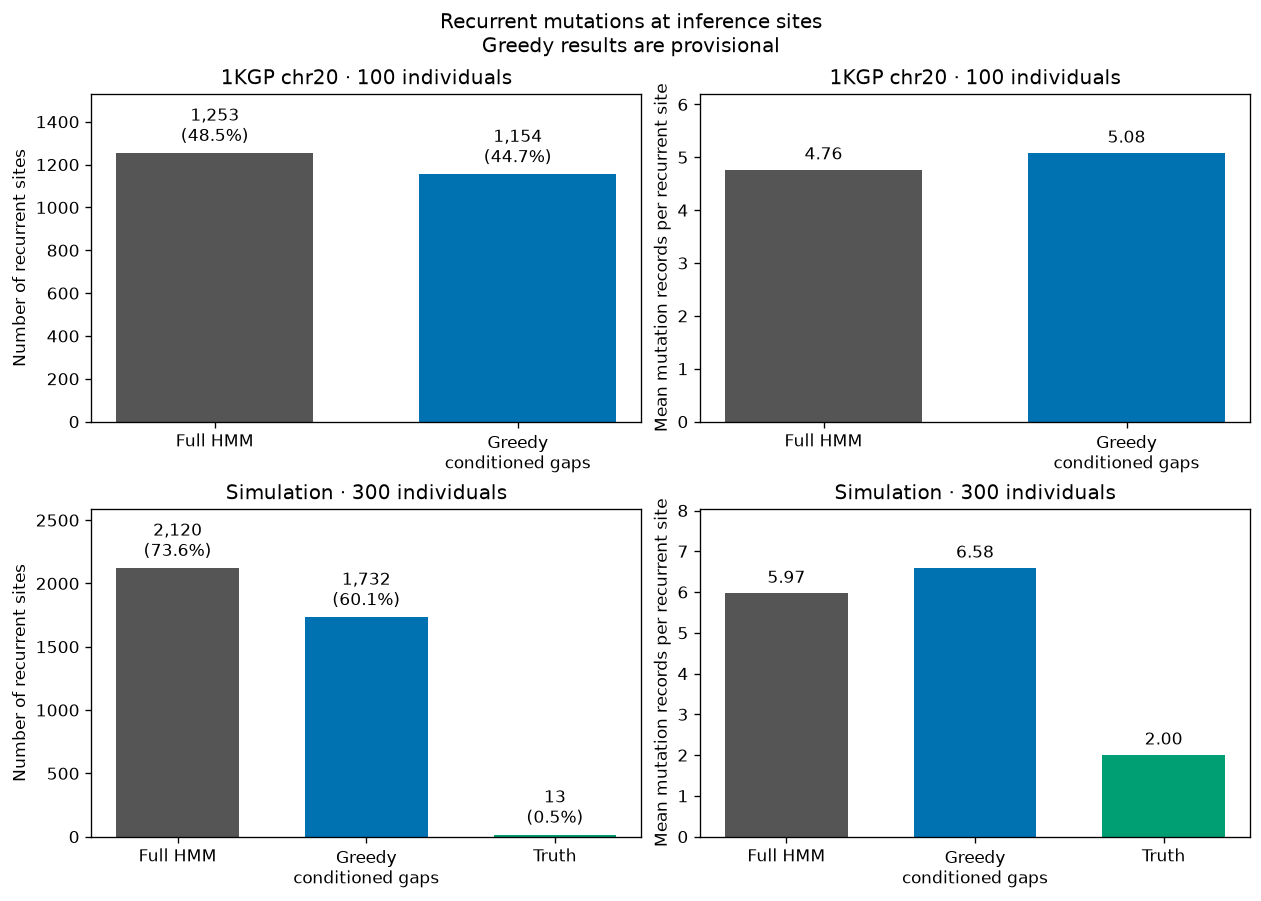

In [4]:
if __name__ == "__main__":
    ipython_display.display(tables.recurrence)
    nb_plot.save_conditioning_figure(
        plot_config,
        nb_plot.plot_conditioned_recurrence(
            plot_config,
            tables.recurrence,
            bar_headroom_fraction=0.22,
            bar_width=0.65,
            dpi=120,
            full_color="#555555",
            greedy_color="#0072B2",
            panel_height=3.7,
            panel_width=5.2,
            provisional_note="Greedy results are provisional",
            truth_color="#009E73",
        ),
        "recurrent_sites",
        export_dpi=180,
    )

## Which recurrent sites and mutations overlap known errors?

In this saved snapshot, `call_genotype_error_mask` has **True = injected
error**. We verify its polarity against the companion error-free raw Zarr
and `variant_genotype_error_count`; the current generator's opposite mask
convention does not describe these saved data. It was recorded **before**
phasing; where `call_genotype_phase` is true,
swap the mask's two haplotype columns to align it with observed calls. These
flags identify **injected genotype errors**, not phase-switch errors or
erroneous ancestor states. Real 1KGP has no corresponding truth mask.

First compare sets of sites: recurrent sites versus inference sites with at
least one injected genotype error among the selected individuals. Circle
areas are schematic. A shared site does not prove every mutation there is
an error. The mutation plot therefore counts direct sample mutation records
at flagged calls separately from sample records without an injected genotype error and
internal/reference records, which have no unique individual call assignment.
Even a direct overlap is not causal proof that the event was introduced by
that error; biological recurrence and errors can coexist.

,dataset,label,method,num_sites,recurrent_only_sites,overlap_sites,error_only_sites,neither_sites,recurrent_sample_mutations,recurrent_sample_mutations_at_error_calls,recurrent_sample_mutations_at_other_calls,recurrent_reference_mutations
0,out_of_africa_n300_500kb_error,Simulation · 300 individuals,full_hmm,2881,1106,1014,20,741,3257,1429,1828,9390
1,out_of_africa_n300_500kb_error,Simulation · 300 individuals,greedy,2881,830,902,132,1017,2401,1219,1182,9002


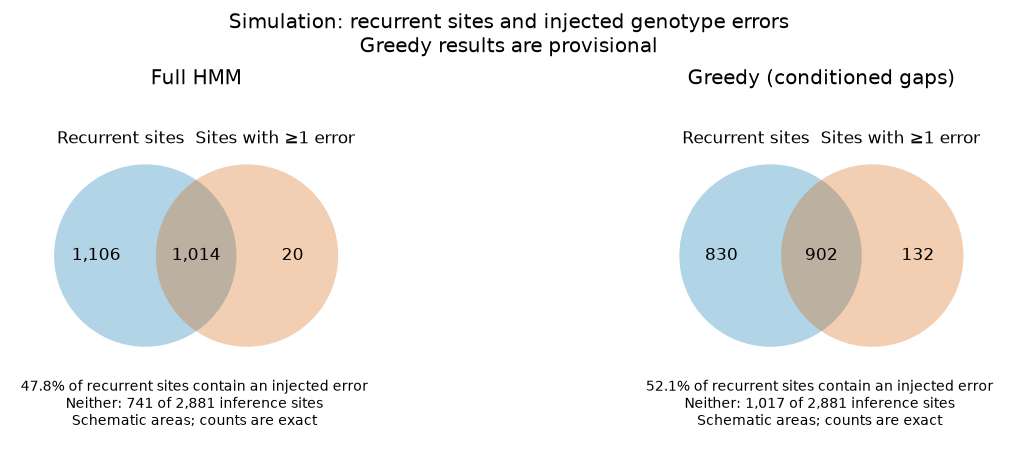

In [5]:
if __name__ == "__main__":
    ipython_display.display(tables.overlap)
    nb_plot.save_conditioning_figure(
        plot_config,
        nb_plot.plot_conditioned_error_sites(
            plot_config,
            tables.overlap,
            dpi=120,
            error_color="#D55E00",
            greedy_color="#0072B2",
            panel_height=3.7,
            panel_width=5.2,
            provisional_note="Greedy results are provisional",
        ),
        "recurrent_error_site_overlap",
        export_dpi=180,
    )

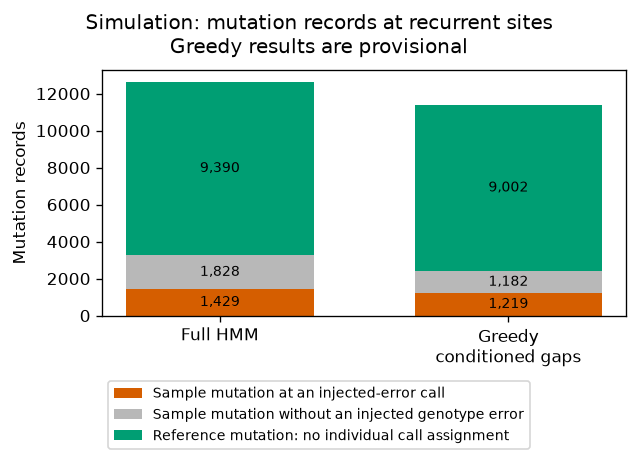

In [6]:
if __name__ == "__main__":
    nb_plot.save_conditioning_figure(
        plot_config,
        nb_plot.plot_conditioned_recurrent_mutation_errors(
            plot_config,
            tables.overlap,
            bar_width=0.65,
            dpi=120,
            error_color="#D55E00",
            other_color="#B8B8B8",
            panel_height=3.7,
            panel_width=5.2,
            provisional_note="Greedy results are provisional",
            truth_color="#009E73",
        ),
        "recurrent_mutation_error_overlap",
        export_dpi=180,
    )

## Mean sample mutations with copying switches stacked above

Count mutation records **on sample nodes** across all inference sites and
copying-parent changes between consecutive inference sites. Unobserved
chromosome flanks do not contribute switches. Sum both haplotypes within
each diploid individual and then average individuals equally. Reference
mutations are excluded from this per-sample statistic. The stack combines
two event counts for comparison; its total is not a likelihood or error score.

,dataset,label,method,switches,mutations
0,tgp_chr20_n100_500kb,1KGP chr20 · 100 individuals,full_hmm,11.01,12.390000
1,tgp_chr20_n100_500kb,1KGP chr20 · 100 individuals,greedy,16.13,12.320000
2,out_of_africa_n300_500kb_error,Simulation · 300 individuals,full_hmm,5.62,10.856667
3,out_of_africa_n300_500kb_error,Simulation · 300 individuals,greedy,15.07,8.003333


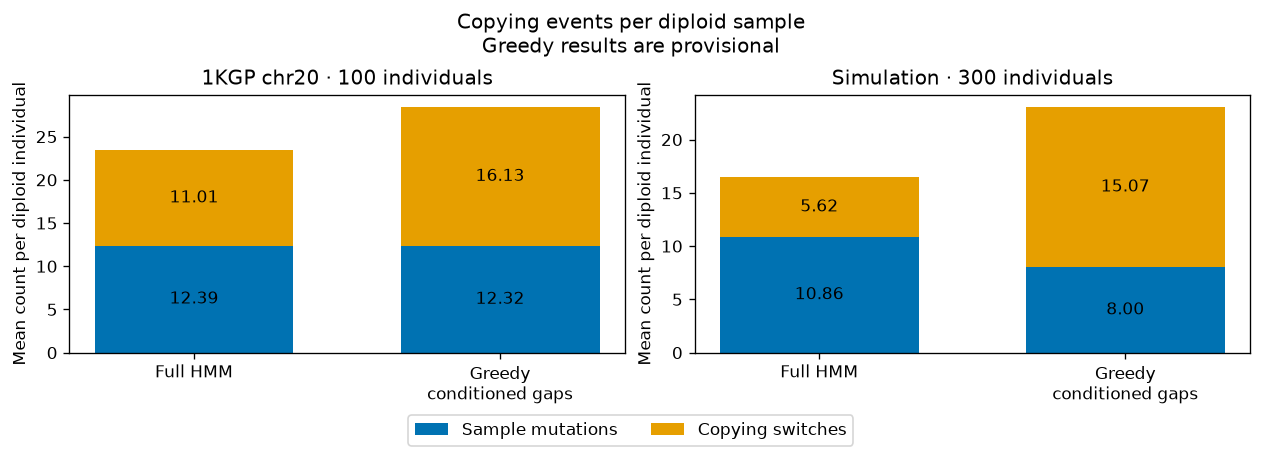

In [7]:
if __name__ == "__main__":
    ipython_display.display(tables.sample_means)
    nb_plot.save_conditioning_figure(
        plot_config,
        nb_plot.plot_conditioned_copying_events(
            plot_config,
            tables.sample_means,
            bar_width=0.65,
            dpi=120,
            greedy_color="#0072B2",
            panel_height=3.7,
            panel_width=5.2,
            provisional_note="Greedy results are provisional",
            switch_color="#E69F00",
        ),
        "sample_mutations_switches",
        export_dpi=180,
    )

## Reading this pilot

In these provisional greedy outputs, greedy has fewer recurrent sites in both datasets, but a higher conditional
mean of mutation records at those recurrent sites, and more copying switches.
In simulation, 47.8% of Full HMM recurrent sites and 52.1% of greedy recurrent
sites overlap at least one injected genotype error. Among direct sample
mutation records at recurrent sites, the corresponding error-call overlaps
are 43.9% and 50.8%. Most recurrent mutation records are on the reference,
so the raw recurrence counts should not be read as counts of sample errors.
The two methods retain the same reference; its contribution to *recurrent*
records differs because their recurrent site sets differ.
These are observations at the chosen p, not evidence that p is optimal.
The allele disagreements above prevent treating the greedy comparison as a
validated result of correctly reproducing all sample calls.


All native configurations, pipeline logs, sample identities, code revisions,
raw trees, CSV tables and PNG/PDF versions of these figures are saved under
`data/ch5/stitching_pt12_conditioning/`. The paired `.py` is the editable
notebook source; rerunning reuses completed pipeline products.